# OptiMatrix Lab: Algebra Lineare Avanzata e Programmazione Lineare

Questo notebook raccoglie implementazioni di algebra lineare avanzata (SVD e Minimi Quadrati) e ottimizzazione lineare vincolata con risoluzione geometrica.

---
## 1. Setup Ambiente

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)

## 2. SVD e Minimi Quadrati

Valori Singolari (S): [41.48583558  3.54949515]
Numero di condizionamento: 11.69
Ricostruzione A = U diag(S) V^T corretta: True
Intercetta: 1.1289 | Pendenza: 2.3840
Soluzione via SVD uguale a lstsq: True


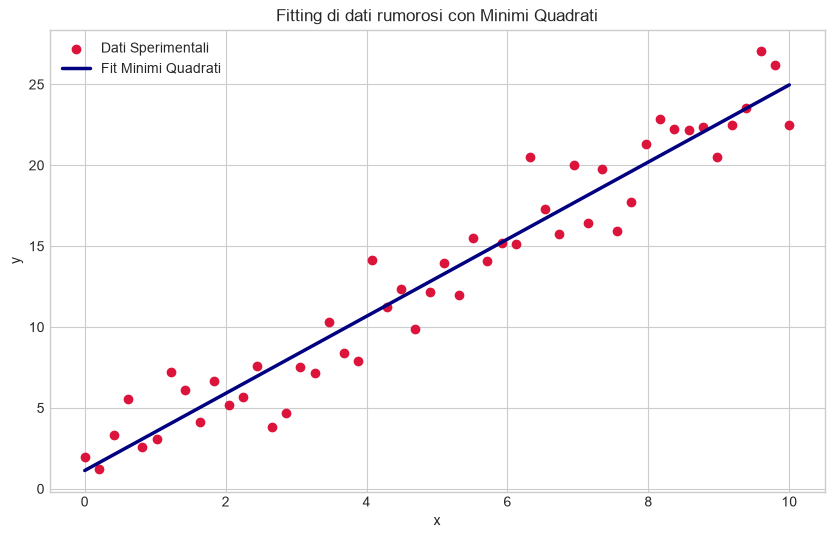

In [2]:
np.random.seed(42)
X_data = np.linspace(0, 10, 50)
y_data = 2.5 * X_data + 1.0 + np.random.normal(0, 2.0, size=X_data.shape)

A = np.column_stack([np.ones_like(X_data), X_data])
b = y_data

# Decomposizione SVD
U, S, Vt = np.linalg.svd(A, full_matrices=False)
print("Valori Singolari (S):", S)
print(f"Numero di condizionamento: {S[0] / S[-1]:.2f}")
print("Ricostruzione A = U diag(S) V^T corretta:", np.allclose(A, U @ np.diag(S) @ Vt))

# Minimi Quadrati tramite pseudo-inversa: x = V diag(1/S) U^T b
x_svd = Vt.T @ ((U.T @ b) / S)

# Minimi Quadrati
x_lstsq, _, _, _ = np.linalg.lstsq(A, b, rcond=None)
print(f"Intercetta: {x_lstsq[0]:.4f} | Pendenza: {x_lstsq[1]:.4f}")
print("Soluzione via SVD uguale a lstsq:", np.allclose(x_svd, x_lstsq))

plt.figure()
plt.scatter(X_data, y_data, color='crimson', label='Dati Sperimentali')
plt.plot(X_data, A @ x_lstsq, color='navy', linewidth=2.5, label='Fit Minimi Quadrati')
plt.title('Fitting di dati rumorosi con Minimi Quadrati')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

## 3. Programmazione Lineare 2D

Ottimo trovato in (x0, x1) = (2.67, 2.67) con valore 21.33


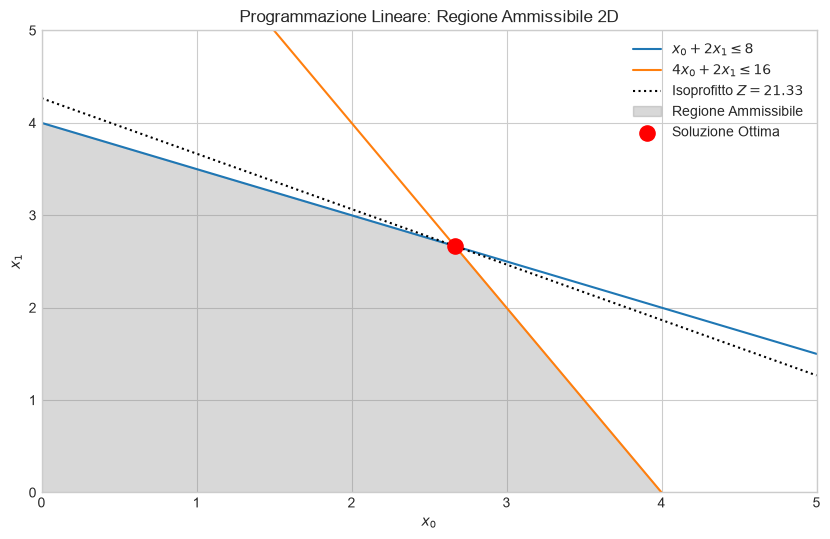

In [3]:
# Massimizzare Z = 3*x0 + 5*x1  ==> Minimizzare -3*x0 - 5*x1
c = [-3, -5]
A_ub = [[1, 2], [4, 2]]
b_ub = [8, 16]

res = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=[(0, None), (0, None)], method='highs')
assert res.success, res.message
print(f"Ottimo trovato in (x0, x1) = ({res.x[0]:.2f}, {res.x[1]:.2f}) con valore {-res.fun:.2f}")

# Grafico Regione Ammissibile
x0_vals = np.linspace(0, 5, 400)
y1 = (8 - x0_vals) / 2.0
y2 = (16 - 4*x0_vals) / 2.0

plt.figure()
plt.plot(x0_vals, y1, label=r'$x_0 + 2x_1 \leq 8$')
plt.plot(x0_vals, y2, label=r'$4x_0 + 2x_1 \leq 16$')
y_pass = np.minimum(y1, y2)
# Retta di isoprofitto 3*x0 + 5*x1 = Z* passante per l'ottimo
plt.plot(x0_vals, (-res.fun - 3 * x0_vals) / 5, 'k:', label=f'Isoprofitto $Z = {-res.fun:.2f}$')
plt.fill_between(x0_vals, 0, np.maximum(0, y_pass), where=(y_pass >= 0), color='gray', alpha=0.3, label='Regione Ammissibile')
plt.scatter(res.x[0], res.x[1], color='red', s=120, zorder=5, label='Soluzione Ottima')
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xlabel('$x_0$')
plt.ylabel('$x_1$')
plt.legend()
plt.title('Programmazione Lineare: Regione Ammissibile 2D')
plt.show()